# IMDb Movie Review Sentiment Analysis

## NLP — Task 1 & Task 2

### Project Overview

This project focuses on Natural Language Processing (NLP)
for binary sentiment classification using the IMDb Large
Movie Review Dataset.

The objective is to analyze movie reviews and classify
their expressed sentiment into two categories:
Positive and Negative.

The project covers two main stages:

**Task 1 — Data Preparation and Text Preprocessing**

This stage focuses on loading the IMDb dataset, examining
its structure, cleaning review text, applying text
preprocessing techniques, and converting textual data
into numerical sequences.

**Task 2 — Feature Extraction and Classification**

This stage builds a consistent dataset for classification,
applies negation-aware text preprocessing, generates
numerical text representations using TF-IDF and Tokenization,
and compares SVM and Naive Bayes baselines with Simple RNN,LSTM and GRU models.

### Dataset

**IMDb Large Movie Review Dataset (aclImdb)**

The dataset contains movie reviews labeled as positive
(`pos`) or negative (`neg`).

### Project Workflow

1. Dataset Loading and Exploration
2. Data Cleaning
3. Text Preprocessing
4. Tokenization and Sequence Preparation
5. Shared Dataset Preparation
6. Negation-Aware Preprocessing
7. Train-Test Splitting
8. Text Feature Extraction
9. SVM and Naive Bayes Model Training and Prediction
10. Simple RNN,LSTM and GRU Model Training and Evaluation
11. Five-Model Performance Comparison

## Notebook Contents

1. Environment setup and imports
2. **Task 1 –** IMDb data loading and inspection
3. **Task 1 –** Cleaning and text preprocessing
4. **Task 1 –** Tokenization, sequence checks, and padding
5. **Task 2 –** Shared dataset preparation
6. **Task 2 –** Negation-aware preprocessing
7. **Task 2 –** One stratified train/test split
8. **Task 2 –** TF-IDF and Tokenizer/Padding features
9. **Task 2 –** SVM training and predictions
10. **Task 2 –** Naive Bayes training and predictions
11. **Task 2 –** Simple RNN training and evaluation
12. **Task 2 –** LSTM training and evaluation
13. **Task 2 –** GRU training and evaluation
14. **Task 2 –** Five-model comparison
15. **Task 2 –**  Unseen movie review predictions


## 1. Environment Setup and Dependencies

This section initializes the Python environment by installing
the libraries required throughout the project.

The dependencies cover data manipulation, visualization,
natural language processing, traditional machine learning,
and deep learning.

The same environment is used across both tasks to maintain
consistency during data preparation and model development.

In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn nltk tensorflow

  Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl.metadata (11 kB)
  Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl.metadata (60 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached scikit_learn-1.7.2-cp310-cp310-win_amd64.whl (8.9 MB)
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------------------ --------------------- 0.8/1.7 MB 2.2 MB/s eta 0:00:01
   ------------------------ --------------- 1.0/1.7 MB 2.3 MB/s eta 0:00:01
   ---------------------------------------- 1.7/1.7 MB 2.2 MB/s  0:00:00
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached scipy-1.15.3-cp310-cp310-win_amd64.whl (41.3 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)

   ---

### Library Imports

The required libraries are imported and organized according
to their roles in the project.

- **Standard Library:** File handling, text operations, and timing.
- **Data Handling:** NumPy and Pandas for numerical operations
  and structured data manipulation.
- **Visualization:** Matplotlib and Seaborn for graphical analysis.
- **NLP:** NLTK for tokenization, stopword removal, and lemmatization.
- **Machine Learning:** Scikit-learn for feature extraction,
  model training, and evaluation.
- **Deep Learning:** TensorFlow and Keras for sequence-based
  neural network models.

In [2]:
# Standard library
import os
import re
import time
import random
import string
import warnings
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# NLP
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Deep Learning
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, SimpleRNN, LSTM, GRU, Dense, Dropout
)

warnings.filterwarnings("ignore")
print("All libraries imported successfully.")

All libraries imported successfully.


### Reproducibility Configuration

A fixed random seed (`SEED = 3`) is applied to Python,
NumPy, and TensorFlow.

This configuration helps make randomized operations
more consistent across repeated executions, supporting
reproducibility during data preparation and model training.

In [3]:
SEED = 3

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Random seed:", SEED)

Random seed: 3


### NLTK Language Resources

The required NLTK resources are downloaded and initialized to support text processing operations.

These resources provide the language data needed for tokenization, stopword removal, and lemmatization throughout the preprocessing workflow.

In [4]:
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

print("NLTK resources are ready.")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Msi\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Msi\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Msi\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Msi\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Msi\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Msi\AppData\Roaming\nltk_data...


NLTK resources are ready.


# Task 1 — Data Loading and Exploration

## 2. IMDb Dataset

The IMDb Large Movie Review Dataset contains movie reviews labeled according to their sentiment.

The dataset is organized into training and testing directories, with separate folders for positive (`pos`) and negative (`neg`) reviews.

Each text file represents one movie review, while its directory determines the corresponding sentiment label.

In [12]:
DATASET_PATH = Path("Data") / "aclImdb_v1" / "aclImdb"

if not all(
    (DATASET_PATH / split / label).is_dir()
    for split in ["train", "test"]
    for label in ["pos", "neg"]
):
    raise FileNotFoundError("IMDb dataset structure is incorrect.")

print("Dataset folder:", DATASET_PATH.resolve())
print("Dataset found successfully!")


Dataset folder: C:\Users\Msi\Downloads\IMDb-Sentiment-Analysis-main\IMDb-Sentiment-Analysis-main\Data\aclImdb_v1\aclImdb
Dataset found successfully!


### Loading Review Text and Sentiment Labels

The review files are read from both training and testing directories.

Each review is stored as raw text together with its corresponding sentiment label. The original text is preserved in `raw_review` to support the independent preprocessing workflow used in Task 2.

In [13]:
def load_reviews(split):
    rows = []

    for sentiment in ["pos", "neg"]:
        folder = DATASET_PATH / split / sentiment

        for file_path in sorted(folder.glob("*.txt")):
            raw_text = file_path.read_text(
                encoding="utf-8",
                errors="replace"
            )

            rows.append({
                "raw_review": raw_text,
                "review": raw_text,
                "sentiment": sentiment
            })

    return rows


data = load_reviews("train") + load_reviews("test")
df = pd.DataFrame(data)

print("Dataset shape:", df.shape)
display(df[["review", "sentiment"]].head())

Dataset shape: (50000, 3)


,review,sentiment
0,Bromwell High is a cartoon comedy. It ran at t...,pos
1,Homelessness (or Houselessness as George Carli...,pos
2,Brilliant over-acting by Lesley Ann Warren. Be...,pos
3,This is easily the most underrated film inn th...,pos
4,This is not the typical Mel Brooks film. It wa...,pos


### Dataset Structure and Initial Inspection

The loaded dataset is examined to understand its dimensions, column data types, missing values, and sentiment distribution.

This initial inspection provides an overview of the dataset quality and verifies that both sentiment classes are represented.

In [14]:
print("Dataset information:")
print("-" * 50)
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nClass distribution:")
print(df["sentiment"].value_counts())

Dataset information:
--------------------------------------------------
Shape: (50000, 3)

Data types:
raw_review    object
review        object
sentiment     object
dtype: object

Missing values:
raw_review    0
review        0
sentiment     0
dtype: int64

Class distribution:
sentiment
pos    25000
neg    25000
Name: count, dtype: int64


### Data Quality Assessment

Missing records and duplicate reviews are identified before proceeding with text preprocessing.

Rows without valid review text or sentiment labels are removed, and duplicate review-label combinations are eliminated.

This ensures that the subsequent preprocessing stages operate on a consistent dataset.

In [15]:
print("Original shape:", df.shape)
print("Duplicated rows:", df.duplicated(subset=["raw_review", "sentiment"]).sum())

df = df.dropna(subset=["raw_review", "sentiment"]).copy()
df = df.drop_duplicates(
    subset=["raw_review", "sentiment"]
).reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Remaining missing values:")
print(df[["raw_review", "sentiment"]].isnull().sum())
print("Remaining duplicates:",
      df.duplicated(subset=["raw_review", "sentiment"]).sum())

Original shape: (50000, 3)
Duplicated rows: 418
Shape after cleaning: (49582, 3)
Remaining missing values:
raw_review    0
sentiment     0
dtype: int64
Remaining duplicates: 0


## 3. Text Preprocessing

Text preprocessing transforms raw movie reviews into a cleaner and more consistent representation.

The following operations prepare the review text for linguistic analysis while preserving the original dataset and sentiment labels.

### Lowercase Normalization

All review text is converted to lowercase to ensure that words with different capitalization are treated as the same token.

For example, `Movie`, `MOVIE`, and `movie` are normalized into `movie`.

In [16]:
df["review"] = df["review"].str.lower()
display(df[["review", "sentiment"]].head())

,review,sentiment
0,bromwell high is a cartoon comedy. it ran at t...,pos
1,homelessness (or houselessness as george carli...,pos
2,brilliant over-acting by lesley ann warren. be...,pos
3,this is easily the most underrated film inn th...,pos
4,this is not the typical mel brooks film. it wa...,pos


### Punctuation Removal

Punctuation marks are removed from the review text to reduce unnecessary textual variations and simplify the tokenization process.

The resulting text contains cleaner word sequences for subsequent NLP operations.

In [17]:
df["review"] = df["review"].str.translate(
    str.maketrans("", "", string.punctuation)
)
display(df[["review", "sentiment"]].head())

,review,sentiment
0,bromwell high is a cartoon comedy it ran at th...,pos
1,homelessness or houselessness as george carlin...,pos
2,brilliant overacting by lesley ann warren best...,pos
3,this is easily the most underrated film inn th...,pos
4,this is not the typical mel brooks film it was...,pos


### Whitespace Normalization

Multiple consecutive spaces, tabs, and newline characters are replaced with a single space.

Leading and trailing whitespace is also removed to maintain a consistent text format.

In [18]:
df["review"] = (
    df["review"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
display(df[["review", "sentiment"]].head())

,review,sentiment
0,bromwell high is a cartoon comedy it ran at th...,pos
1,homelessness or houselessness as george carlin...,pos
2,brilliant overacting by lesley ann warren best...,pos
3,this is easily the most underrated film inn th...,pos
4,this is not the typical mel brooks film it was...,pos


### Word Tokenization

Each preprocessed review is divided into individual words using NLTK's `word_tokenize()` function.

The resulting tokens represent the basic textual units used in the following NLP preprocessing stages.

In [19]:
df["tokens"] = df["review"].apply(word_tokenize)
display(df[["review", "tokens"]].head())

,review,tokens
0,bromwell high is a cartoon comedy it ran at th...,"[bromwell, high, is, a, cartoon, comedy, it, r..."
1,homelessness or houselessness as george carlin...,"[homelessness, or, houselessness, as, george, ..."
2,brilliant overacting by lesley ann warren best...,"[brilliant, overacting, by, lesley, ann, warre..."
3,this is easily the most underrated film inn th...,"[this, is, easily, the, most, underrated, film..."
4,this is not the typical mel brooks film it was...,"[this, is, not, the, typical, mel, brooks, fil..."


### Stopword Removal

Common English stopwords are removed using NLTK's English stopword list.

These frequently occurring words generally contribute less to distinguishing review content.

This step follows the original Task 1 preprocessing workflow. Negation terms are handled differently in Task 2 to preserve sentiment-related meaning.

In [20]:
stop_words_task1 = set(stopwords.words("english"))

df["tokens"] = df["tokens"].apply(
    lambda tokens: [
        word for word in tokens
        if word not in stop_words_task1
    ]
)

display(df[["review", "tokens"]].head())

,review,tokens
0,bromwell high is a cartoon comedy it ran at th...,"[bromwell, high, cartoon, comedy, ran, time, p..."
1,homelessness or houselessness as george carlin...,"[homelessness, houselessness, george, carlin, ..."
2,brilliant overacting by lesley ann warren best...,"[brilliant, overacting, lesley, ann, warren, b..."
3,this is easily the most underrated film inn th...,"[easily, underrated, film, inn, brooks, cannon..."
4,this is not the typical mel brooks film it was...,"[typical, mel, brooks, film, much, less, slaps..."


### Word Lemmatization

Lemmatization reduces words to their base dictionary form using NLTK's WordNetLemmatizer.

This step groups different grammatical forms of a word under a common representation, reducing vocabulary variations while preserving the underlying meaning.

In [21]:
lemmatizer_task1 = WordNetLemmatizer()

df["tokens"] = df["tokens"].apply(
    lambda tokens: [
        lemmatizer_task1.lemmatize(word)
        for word in tokens
    ]
)

display(df[["review", "tokens"]].head())

,review,tokens
0,bromwell high is a cartoon comedy it ran at th...,"[bromwell, high, cartoon, comedy, ran, time, p..."
1,homelessness or houselessness as george carlin...,"[homelessness, houselessness, george, carlin, ..."
2,brilliant overacting by lesley ann warren best...,"[brilliant, overacting, lesley, ann, warren, b..."
3,this is easily the most underrated film inn th...,"[easily, underrated, film, inn, brook, cannon,..."
4,this is not the typical mel brooks film it was...,"[typical, mel, brook, film, much, less, slapst..."


## 4. Numerical Text Representation

Machine learning models require numerical input rather than raw text.

The preprocessed reviews are therefore converted into sequences of integer indices, where each word is represented by its corresponding vocabulary index.

### Vocabulary Construction and Sequence Encoding

A Keras Tokenizer builds a vocabulary from the processed reviews and assigns a unique integer index to each word.

Each review is then transformed into a sequence of integers representing its words.

In [22]:
df["processed_text_task1"] = df["tokens"].apply(
    lambda tokens: " ".join(tokens)
)

tokenizer_task1 = Tokenizer()
tokenizer_task1.fit_on_texts(df["processed_text_task1"])

sequences_task1 = tokenizer_task1.texts_to_sequences(
    df["processed_text_task1"]
)

print("Vocabulary size:", len(tokenizer_task1.word_index))
print("First sequence:", sequences_task1[0])

Vocabulary size: 170219
First sequence: [28906, 230, 687, 101, 1869, 6, 1550, 264, 31, 1247, 4259, 48, 3481, 5175, 217, 168, 28906, 230, 1813, 18, 2297, 491, 1247, 19493, 1784, 9422, 5049, 672, 14, 108, 1044, 1247, 21660, 33360, 126, 428, 2867, 264, 546, 672, 117, 176, 672, 3036, 638, 1740, 264, 1079, 12087, 230, 227, 116, 3138, 62, 7698, 4, 1247, 672, 2268, 28906, 230, 416, 36, 643, 423, 30, 28906, 230, 138, 7174, 2113, 118]


### Empty Sequence Validation

The generated sequences are checked to identify reviews that contain no tokens after preprocessing.

This validation ensures that the numerical representation contains usable textual information before padding.

In [23]:
empty_sequences_task1 = sum(
    1 for sequence in sequences_task1
    if len(sequence) == 0
)

print("Empty sequences:", empty_sequences_task1)

Empty sequences: 0


### Sequence Padding

Padding is applied to make all review sequences have a consistent length.

Shorter sequences are padded with zeros, while longer sequences are truncated according to the selected maximum length.

The resulting uniform sequences can be processed by neural network architectures.

In [24]:
padded_sequences_task1 = pad_sequences(
    sequences_task1,
    padding="post"
)

print("Padded sequences shape:", padded_sequences_task1.shape)
print("First padded sequence:", padded_sequences_task1[0])

Padded sequences shape: (49582, 1449)
First padded sequence: [28906   230   687 ...     0     0     0]


### Sentiment Label Distribution

The target labels are examined to understand the distribution of positive and negative movie reviews.

This provides an overview of class representation and helps assess whether the dataset is balanced.

In [25]:
df["sentiment"] = df["sentiment"].astype(str)

print("Sentiment distribution:")
print(df["sentiment"].value_counts())
display(df[["review", "sentiment"]].head())

Sentiment distribution:
sentiment
pos    24884
neg    24698
Name: count, dtype: int64


,review,sentiment
0,bromwell high is a cartoon comedy it ran at th...,pos
1,homelessness or houselessness as george carlin...,pos
2,brilliant overacting by lesley ann warren best...,pos
3,this is easily the most underrated film inn th...,pos
4,this is not the typical mel brooks film it was...,pos


# Task 2 — Text Classification and Model Comparison

Task 2 builds on the prepared IMDb reviews by establishing a shared dataset and feature extraction pipeline for supervised sentiment classification.

The workflow uses a consistent train/test split and prepares numerical representations suitable for both traditional machine learning algorithms and recurrent neural networks.

## 5. Shared Dataset Preparation

The original raw reviews and their sentiment labels are organized into a unified DataFrame.

The input text is stored in `statement`, while the corresponding sentiment category is stored in `status`.

Preserving the raw review text allows Task 2 to apply its own preprocessing independently of Task 1.

In [26]:
df_task2 = df[["raw_review", "sentiment"]].copy()

df_task2 = df_task2.rename(columns={
    "raw_review": "statement",
    "sentiment": "status"
})

print("Task 2 dataset shape:", df_task2.shape)
display(df_task2.head())

Task 2 dataset shape: (49582, 2)


,statement,status
0,Bromwell High is a cartoon comedy. It ran at t...,pos
1,Homelessness (or Houselessness as George Carli...,pos
2,Brilliant over-acting by Lesley Ann Warren. Be...,pos
3,This is easily the most underrated film inn th...,pos
4,This is not the typical Mel Brooks film. It wa...,pos


### Dataset Structure and Sentiment Distribution

The shared DataFrame is inspected to verify the required input and target columns.

The number of records and the distribution of sentiment classes are examined to confirm the dataset structure before model preparation.

In [27]:
required_columns = ["statement", "status"]

missing_columns = [
    column for column in required_columns
    if column not in df_task2.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df_task2 = df_task2[required_columns].copy()

print("Shape:", df_task2.shape)
print("\nMissing values:")
print(df_task2.isnull().sum())
print("\nClass distribution:")
print(df_task2["status"].value_counts())

Shape: (49582, 2)

Missing values:
statement    0
status       0
dtype: int64

Class distribution:
status
pos    24884
neg    24698
Name: count, dtype: int64


### Dataset Cleaning and Validation

Missing values, empty review texts, and duplicate records are identified and handled.

The resulting dataset provides consistent input records and valid sentiment labels for the classification pipeline.

In [28]:
print("Original shape:", df_task2.shape)

df_task2 = df_task2.dropna(
    subset=["statement", "status"]
).copy()

df_task2["statement"] = df_task2["statement"].astype(str).str.strip()
df_task2["status"] = df_task2["status"].astype(str).str.strip()

df_task2 = df_task2[
    (df_task2["statement"] != "") &
    (df_task2["status"] != "")
].copy()

df_task2 = df_task2.drop_duplicates(
    subset=["statement", "status"]
).reset_index(drop=True)

print("Shape after cleaning:", df_task2.shape)
print("Remaining duplicates:",
      df_task2.duplicated(subset=["statement", "status"]).sum())

Original shape: (49582, 2)
Shape after cleaning: (49582, 2)
Remaining duplicates: 0


### Sentiment Label Validation

The target labels are checked against the label-merging instruction provided in the Task 2 specification.

Since the IMDb dataset contains `pos` and `neg` sentiment categories rather than `Suicidal` and `Depression`, the original IMDb labels are retained.

In [29]:
df_task2["status"] = df_task2["status"].str.strip().str.lower()

print("Classes before optional merge:")
print(df_task2["status"].value_counts())

if "suicidal" in set(df_task2["status"].unique()):
    df_task2["status"] = df_task2["status"].replace({
        "suicidal": "depression"
    })
    print("\nApplied: suicidal -> depression")
else:
    print(
        "\nNo 'suicidal' label found. "
        "IMDb labels remain unchanged."
    )

print("\nClasses after this step:")
print(df_task2["status"].value_counts())

Classes before optional merge:
status
pos    24884
neg    24698
Name: count, dtype: int64

No 'suicidal' label found. IMDb labels remain unchanged.

Classes after this step:
status
pos    24884
neg    24698
Name: count, dtype: int64


## 6. Negation-Aware Text Preprocessing

A dedicated preprocessing function is applied to the original review text to prepare a consistent representation for all Task 2 models.

Unlike conventional stopword removal, this approach preserves important negation terms such as `not`, `no`, and `never`, since removing them can reverse the sentiment expressed in a review.

In [31]:
stop_words_task2 = set(stopwords.words("english"))
negation_words = {"not", "no", "never"}
stop_words_task2 = stop_words_task2 - negation_words

lemmatizer_task2 = WordNetLemmatizer()


def preprocess_text(text):
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove punctuation while preserving apostrophes
    text = re.sub(r"[^\w\s']", " ", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenization
    tokens = word_tokenize(text)

    # Remove stopwords but preserve negation
    tokens = [
        word for word in tokens
        if word not in stop_words_task2
    ]

    # Lemmatization
    tokens = [
        lemmatizer_task2.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)


df_task2["processed_text"] = df_task2["statement"].apply(
    preprocess_text
)

# Remove empty processed texts before splitting
df_task2 = df_task2[
    df_task2["processed_text"].str.strip() != ""
].reset_index(drop=True)

print("Preprocessing completed.")
print("Dataset shape after preprocessing:", df_task2.shape)
display(df_task2[["statement", "processed_text", "status"]].head())

Preprocessing completed.
Dataset shape after preprocessing: (49582, 3)


,statement,processed_text,status
0,Bromwell High is a cartoon comedy. It ran at t...,bromwell high cartoon comedy ran time program ...,pos
1,Homelessness (or Houselessness as George Carli...,homelessness houselessness george carlin state...,pos
2,Brilliant over-acting by Lesley Ann Warren. Be...,brilliant acting lesley ann warren best dramat...,pos
3,This is easily the most underrated film inn th...,easily underrated film inn brook cannon sure f...,pos
4,This is not the typical Mel Brooks film. It wa...,not typical mel brook film much less slapstick...,pos


### Negation Preservation Validation

The preprocessing function is tested using example sentences containing negation terms.

The resulting text is inspected to verify that important sentiment-reversing words remain available for model training.

In [32]:
test_sentences = [
    "I am not happy",
    "I have no hope",
    "I never feel good"
]

for sentence in test_sentences:
    print("Original:", sentence)
    print("Processed:", preprocess_text(sentence))
    print("-" * 50)

Original: I am not happy
Processed: not happy
--------------------------------------------------
Original: I have no hope
Processed: no hope
--------------------------------------------------
Original: I never feel good
Processed: never feel good
--------------------------------------------------


## 7. Shared Train-Test Split

The cleaned dataset is divided into training and testing subsets using an 80:20 stratified split.

Stratification maintains the original class proportions in both subsets.

A fixed random state ensures reproducibility, while the shared split allows all classification models to be evaluated on the same data.

In [33]:
X = df_task2["processed_text"]
y = df_task2["status"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=3,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 39665
Testing samples: 9917

Training distribution:
status
pos    19907
neg    19758
Name: count, dtype: int64

Testing distribution:
status
pos    4977
neg    4940
Name: count, dtype: int64


### Numerical Target Encoding

The categorical sentiment labels are converted into numerical values to make them suitable for model training.

The class mapping is retained so that numerical predictions can later be interpreted as their original sentiment categories.

In [34]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

class_names = label_encoder.classes_
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)
print("Encoded training labels:", y_train_encoded[:10])
print("Encoded testing labels:", y_test_encoded[:10])

Classes: ['neg' 'pos']
Number of classes: 2
Encoded training labels: [0 1 1 0 0 0 1 0 0 0]
Encoded testing labels: [1 1 1 0 0 1 1 0 1 0]


## 8. Text Feature Extraction

Two numerical representations are prepared to support the different model architectures.

- **TF-IDF:** Represents reviews as weighted word-feature vectors for traditional machine learning models.
- **Tokenizer and Padding:** Converts reviews into fixed-length integer sequences for recurrent neural networks.

Both representations are fitted using training data only to prevent information leakage from the test set.

### TF-IDF Feature Representation

Term Frequency–Inverse Document Frequency (TF-IDF) converts review text into numerical feature vectors.

It assigns weights based on word frequency within a review and the importance of each word across the document collection.

The fitted vectorizer transforms both training and testing reviews into a shared feature space.

In [35]:
MAX_FEATURES = 10000

tfidf_vectorizer = TfidfVectorizer(
    max_features=MAX_FEATURES
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))

TF-IDF training shape: (39665, 10000)
TF-IDF testing shape: (9917, 10000)
Vocabulary size: 10000


### Tokenizer-Based Sequence Representation

A Keras Tokenizer builds a vocabulary using the training reviews and converts the text into integer sequences.

Padding is then applied to produce uniform-length sequences suitable for RNN, LSTM, and GRU architectures.

The same fitted tokenizer and sequence length are used to transform the testing reviews.

In [36]:
MAX_WORDS = 10000
MAX_LENGTH = 200
EMBEDDING_DIM = 64

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

train_sequences = tokenizer.texts_to_sequences(X_train)
test_sequences = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    train_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    test_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Tokenizer vocabulary size:", len(tokenizer.word_index))
print("Training sequence shape:", X_train_pad.shape)
print("Testing sequence shape:", X_test_pad.shape)

Tokenizer vocabulary size: 84098
Training sequence shape: (39665, 200)
Testing sequence shape: (9917, 200)


# Part III — SVM Classification

## 9. Support Vector Machine (SVM)

A Support Vector Machine (SVM) is implemented as the traditional machine learning baseline for IMDb sentiment classification.

The model uses the TF-IDF feature representation to learn the relationship between review text and sentiment labels.

The trained classifier is evaluated using the held-out test dataset.

### SVM Model Initialization

A Linear Support Vector Classifier (`LinearSVC`) is initialized to perform binary sentiment classification.

The model is configured to learn a linear decision boundary that separates positive and negative reviews based on their TF-IDF features.

In [37]:
svm_model = LinearSVC()
print("SVM model initialized successfully.")

SVM model initialized successfully.


### Model Training and Execution Time

The SVM classifier is fitted using the training TF-IDF feature matrix and its corresponding sentiment labels.

The training duration is measured to record the computational time required to fit the model.

In [38]:
start_time = time.time()

svm_model.fit(
    X_train_tfidf,
    y_train
)

svm_train_time = time.time() - start_time

print("SVM training completed.")
print(f"Training time: {svm_train_time:.4f} seconds")

SVM training completed.
Training time: 1.2921 seconds


### Sentiment Prediction

The trained SVM model generates sentiment predictions for the unseen test reviews.

The predicted labels are stored for comparison with the actual test labels and subsequent model evaluation.

In [39]:
svm_predictions = svm_model.predict(X_test_tfidf)

print("SVM predictions generated.")
print("First 10 predictions:", svm_predictions[:10])
print("First 10 actual labels:", y_test.to_numpy()[:10])

SVM predictions generated.
First 10 predictions: ['pos' 'pos' 'pos' 'neg' 'neg' 'pos' 'pos' 'neg' 'pos' 'pos']
First 10 actual labels: ['pos' 'pos' 'pos' 'neg' 'neg' 'pos' 'pos' 'neg' 'pos' 'neg']


### Actual vs. Predicted Sentiment

The actual sentiment labels are compared with the predictions generated by the trained SVM classifier.

Displaying individual review examples provides an initial inspection of the model's classification behavior and prediction errors.

In [40]:
svm_results = pd.DataFrame({
    "Review": X_test.to_numpy()[:10],
    "Actual Sentiment": y_test.to_numpy()[:10],
    "Predicted Sentiment": svm_predictions[:10]
})

display(svm_results)

,Review,Actual Sentiment,Predicted Sentiment
0,sunday july 16 8 00pm castro san francisco sou...,pos,pos
1,year puzzled julie brown west coast n't househ...,pos,pos
2,went wal mart found film dvd no idea whether m...,pos,pos
3,watched acacia find agree negative review like...,neg,neg
4,shocked 18 page good review one worst movie es...,neg,neg
5,sure 's 50 's drive special n't let fool littl...,pos,pos
6,movie wonderful show man 's work wilderness na...,pos,pos
7,dont ever ever ever consider watching sorry ex...,neg,neg
8,kurt russell elvis plain simple dedication rol...,pos,pos
9,woody allen seems completely devoid inspiratio...,neg,pos


## 10. SVM Model Evaluation

The trained Support Vector Machine (SVM) classifier is evaluated using the held-out test dataset.

The evaluation measures the model's performance through Accuracy, Macro Precision, Macro Recall, Macro F1-score, and Weighted F1-score.

A classification report provides a detailed summary of the performance across sentiment classes, while the confusion matrix visualizes the distribution of correct and incorrect predictions.

The same class order is maintained across evaluation outputs to ensure consistency when comparing the classification models.
:::

In [41]:
# Define a reusable evaluation function for classification models

def evaluate_model(model_name, y_true, y_pred, train_time):

    # Calculate evaluation metrics
    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred,
            labels=class_names,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred,
            labels=class_names,
            average="macro",
            zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred,
            labels=class_names,
            average="macro",
            zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, y_pred,
            labels=class_names,
            average="weighted",
            zero_division=0
        ),
        "Training Time (seconds)": train_time
    }

    # Display evaluation metrics
    print(f"{model_name} - Evaluation Metrics")
    print("-" * 50)

    for metric, value in metrics.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

    # Display classification report
    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=class_names,
            target_names=class_names,
            zero_division=0
        )
    )

    # Generate confusion matrix
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_names
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

    return metrics

SVM - Evaluation Metrics
--------------------------------------------------
Accuracy: 0.8912
Macro Precision: 0.8913
Macro Recall: 0.8912
Macro F1: 0.8912
Weighted F1: 0.8912
Training Time (seconds): 1.2921

Classification Report:
              precision    recall  f1-score   support

         neg       0.90      0.88      0.89      4940
         pos       0.89      0.90      0.89      4977

    accuracy                           0.89      9917
   macro avg       0.89      0.89      0.89      9917
weighted avg       0.89      0.89      0.89      9917



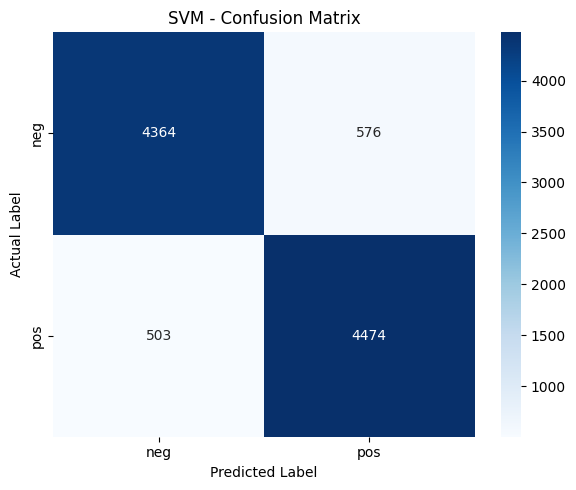

In [42]:
# Evaluate the trained SVM model

svm_metrics = evaluate_model(
    model_name="SVM",
    y_true=y_test,
    y_pred=svm_predictions,
    train_time=svm_train_time
)

## 11. Naive Bayes Classification

Naive Bayes is implemented as the second traditional machine learning classifier for IMDb sentiment analysis.

The model applies Bayes' theorem with a conditional independence assumption between features.

Multinomial Naive Bayes is suitable for text classification tasks and uses the TF-IDF feature representation to classify reviews into positive and negative sentiment categories.

The model is trained using the same training dataset and evaluated on the same held-out test dataset used for SVM, ensuring a fair comparison.

### Naive Bayes Model Initialization

A Multinomial Naive Bayes classifier is initialized to perform binary sentiment classification.

The classifier uses the TF-IDF feature vectors prepared earlier and learns the relationship between word features and sentiment labels from the training data.

In [43]:
# Initialize the Multinomial Naive Bayes classifier

nb_model = MultinomialNB()

print("Naive Bayes model initialized successfully.")

Naive Bayes model initialized successfully.


### Naive Bayes Model Training and Execution Time

The Multinomial Naive Bayes classifier is trained using the TF-IDF training feature matrix and its corresponding sentiment labels.

The training duration is measured to record the computational time required to fit the model.

The fitted classifier learns the statistical relationships between the extracted text features and the sentiment categories.

In [44]:
# Train the Naive Bayes classifier and measure execution time

start_time = time.time()

nb_model.fit(
    X_train_tfidf,
    y_train
)

nb_train_time = time.time() - start_time

print("Naive Bayes training completed.")
print(f"Training time: {nb_train_time:.4f} seconds")

Naive Bayes training completed.
Training time: 0.1978 seconds


### Naive Bayes Sentiment Prediction

The trained Naive Bayes classifier generates sentiment predictions for the unseen test reviews.

The previously fitted TF-IDF vectorizer is reused to represent the test data, ensuring that the model receives features in the same representation used during training.

In [45]:
# Generate sentiment predictions using Naive Bayes

nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes predictions generated.")
print("First 10 predictions:", nb_predictions[:10])
print("First 10 actual labels:", y_test.to_numpy()[:10])

Naive Bayes predictions generated.
First 10 predictions: ['pos' 'pos' 'pos' 'neg' 'neg' 'pos' 'pos' 'neg' 'pos' 'pos']
First 10 actual labels: ['pos' 'pos' 'pos' 'neg' 'neg' 'pos' 'pos' 'neg' 'pos' 'neg']


### Actual vs. Predicted Sentiment

The actual sentiment labels are compared with the predictions generated by the trained Naive Bayes classifier.

Displaying individual review examples provides an initial inspection of the model's classification behavior and prediction errors.

In [46]:
# Compare actual and predicted sentiment labels

nb_results = pd.DataFrame({
    "Review": X_test.to_numpy()[:10],
    "Actual Sentiment": y_test.to_numpy()[:10],
    "Predicted Sentiment": nb_predictions[:10]
})

display(nb_results)

,Review,Actual Sentiment,Predicted Sentiment
0,sunday july 16 8 00pm castro san francisco sou...,pos,pos
1,year puzzled julie brown west coast n't househ...,pos,pos
2,went wal mart found film dvd no idea whether m...,pos,pos
3,watched acacia find agree negative review like...,neg,neg
4,shocked 18 page good review one worst movie es...,neg,neg
5,sure 's 50 's drive special n't let fool littl...,pos,pos
6,movie wonderful show man 's work wilderness na...,pos,pos
7,dont ever ever ever consider watching sorry ex...,neg,neg
8,kurt russell elvis plain simple dedication rol...,pos,pos
9,woody allen seems completely devoid inspiratio...,neg,pos


### Naive Bayes Model Evaluation

The Naive Bayes classifier is evaluated using the same held-out test dataset used for the SVM model.

Performance is measured using Accuracy, Macro Precision, Macro Recall, Macro F1-score, and Weighted F1-score.

The classification report summarizes the model's performance for each sentiment class, while the confusion matrix illustrates the correct and incorrect predictions.

The same evaluation procedure and class ordering are maintained to ensure a fair comparison between both traditional machine learning classifiers.

Naive Bayes - Evaluation Metrics
--------------------------------------------------
Accuracy: 0.8605
Macro Precision: 0.8606
Macro Recall: 0.8605
Macro F1: 0.8605
Weighted F1: 0.8605
Training Time (seconds): 0.1978

Classification Report:
              precision    recall  f1-score   support

         neg       0.86      0.86      0.86      4940
         pos       0.86      0.86      0.86      4977

    accuracy                           0.86      9917
   macro avg       0.86      0.86      0.86      9917
weighted avg       0.86      0.86      0.86      9917



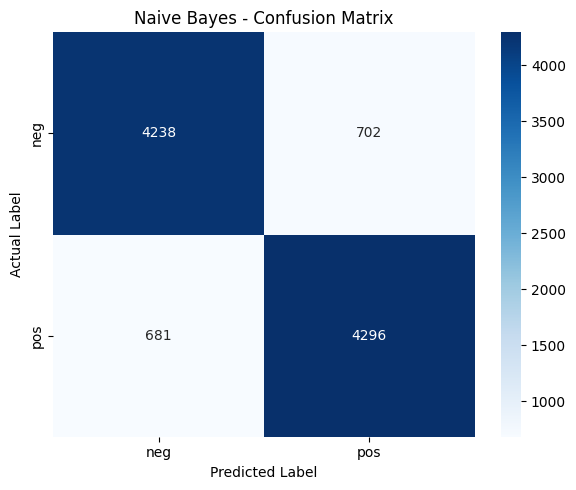

In [47]:
# Evaluate the trained Naive Bayes model

nb_metrics = evaluate_model(
    model_name="Naive Bayes",
    y_true=y_test,
    y_pred=nb_predictions,
    train_time=nb_train_time
)

## 12. Simple RNN Classification

The Simple RNN reuses the training-only tokenizer and padded sequences. A validation fraction is drawn from the training data; the held-out test set is reserved for final evaluation. Early stopping restores the best validation-loss weights.


In [48]:
# Build a Simple RNN for binary sentiment classification
rnn_model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_LENGTH),
    SimpleRNN(64),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
], name="simple_rnn_sentiment")

rnn_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
rnn_model.summary()


Model: "simple_rnn_sentiment"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [49]:
# Train with validation data drawn only from the training split
early_stopping_rnn = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

start_time = time.time()
rnn_history = rnn_model.fit(
    X_train_pad, y_train_encoded,
    validation_split=0.2, epochs=5, batch_size=128,
    callbacks=[early_stopping_rnn], shuffle=True, verbose=1
)
rnn_train_time = time.time() - start_time
print(f"Simple RNN training completed in {rnn_train_time:.2f} seconds.")


Epoch 1/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 16s 35ms/step - accuracy: 0.5006 - loss: 0.6967 - val_accuracy: 0.4986 - val_loss: 0.6929
Epoch 2/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - accuracy: 0.5390 - loss: 0.6853 - val_accuracy: 0.5086 - val_loss: 0.6946
Epoch 3/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.5317 - loss: 0.7124 - val_accuracy: 0.5074 - val_loss: 0.6942
Simple RNN training completed in 32.79 seconds.


In [50]:
# Decode neural predictions to match the string labels used by evaluate_model
rnn_probabilities = rnn_model.predict(X_test_pad, batch_size=128, verbose=1).ravel()
rnn_predictions_encoded = (rnn_probabilities >= 0.5).astype(int)
rnn_predictions = label_encoder.inverse_transform(rnn_predictions_encoded)
print("Simple RNN predictions generated.")
print("First 10 predictions:", rnn_predictions[:10])
print("First 10 actual labels:", y_test.to_numpy()[:10])


78/78 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step
Simple RNN predictions generated.
First 10 predictions: ['pos' 'neg' 'neg' 'neg' 'pos' 'neg' 'neg' 'neg' 'neg' 'neg']
First 10 actual labels: ['pos' 'pos' 'pos' 'neg' 'neg' 'pos' 'pos' 'neg' 'pos' 'neg']


Simple RNN - Evaluation Metrics
--------------------------------------------------
Accuracy: 0.5017
Macro Precision: 0.5053
Macro Recall: 0.5029
Macro F1: 0.4394
Weighted F1: 0.4387
Training Time (seconds): 32.7923

Classification Report:
              precision    recall  f1-score   support

         neg       0.50      0.84      0.63      4940
         pos       0.51      0.17      0.25      4977

    accuracy                           0.50      9917
   macro avg       0.51      0.50      0.44      9917
weighted avg       0.51      0.50      0.44      9917



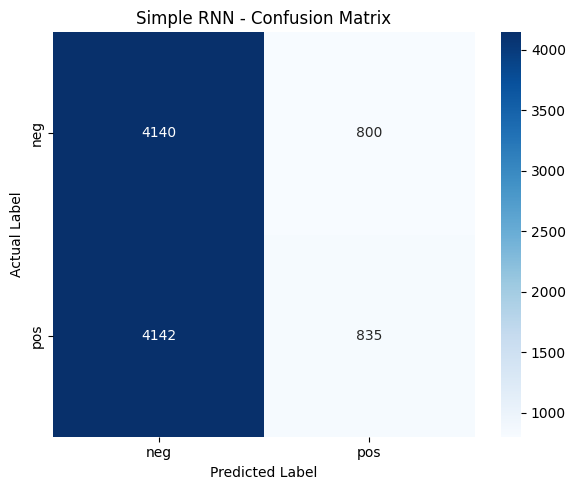

In [52]:
# Evaluate the Simple RNN on the shared held-out test set
rnn_metrics = evaluate_model("Simple RNN", y_test, rnn_predictions, rnn_train_time)


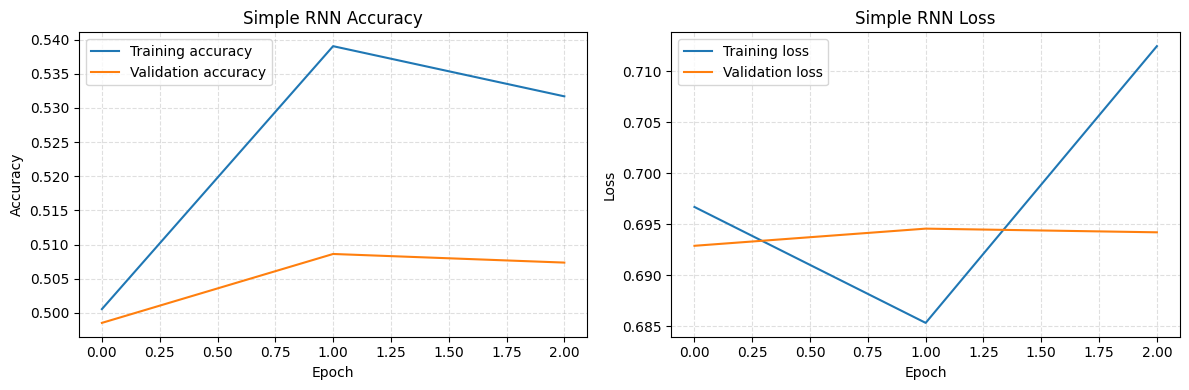

In [53]:
# Plot Simple RNN training and validation accuracy and loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(rnn_history.history["accuracy"], label="Training accuracy")
axes[0].plot(rnn_history.history["val_accuracy"], label="Validation accuracy")
axes[0].set(title="Simple RNN Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[0].legend(); axes[0].grid(True, linestyle="--", alpha=0.4)
axes[1].plot(rnn_history.history["loss"], label="Training loss")
axes[1].plot(rnn_history.history["val_loss"], label="Validation loss")
axes[1].set(title="Simple RNN Loss", xlabel="Epoch", ylabel="Loss")
axes[1].legend(); axes[1].grid(True, linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()


## 13. LSTM Classification

The LSTM uses the same padded sequences, training labels, and held-out test split as the Simple RNN. Validation comes from the training split only, and EarlyStopping restores the best validation-loss weights.


In [54]:
# Build an LSTM for binary sentiment classification
lstm_model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_LENGTH),
    LSTM(64),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
], name="lstm_sentiment")

lstm_model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
lstm_model.summary()


Model: "lstm_sentiment"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [55]:
# Train with validation data drawn only from the training split
early_stopping_lstm = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

start_time = time.time()
lstm_history = lstm_model.fit(
    X_train_pad, y_train_encoded,
    validation_split=0.2, epochs=5, batch_size=128,
    callbacks=[early_stopping_lstm], shuffle=True, verbose=1
)
lstm_train_time = time.time() - start_time
print(f"LSTM training completed in {lstm_train_time:.2f} seconds.")


Epoch 1/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 28s 103ms/step - accuracy: 0.5085 - loss: 0.6931 - val_accuracy: 0.5127 - val_loss: 0.6917
Epoch 2/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 25s 103ms/step - accuracy: 0.5363 - loss: 0.6905 - val_accuracy: 0.5156 - val_loss: 0.6920
Epoch 3/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 25s 101ms/step - accuracy: 0.5707 - loss: 0.6724 - val_accuracy: 0.5187 - val_loss: 0.6913
Epoch 4/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 25s 99ms/step - accuracy: 0.5642 - loss: 0.6758 - val_accuracy: 0.5260 - val_loss: 0.6825
Epoch 5/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - accuracy: 0.5507 - loss: 0.6623 - val_accuracy: 0.5478 - val_loss: 0.6638
LSTM training completed in 130.04 seconds.


In [56]:
# Decode neural predictions to match the string labels used by evaluate_model
lstm_probabilities = lstm_model.predict(X_test_pad, batch_size=128, verbose=1).ravel()
lstm_predictions_encoded = (lstm_probabilities >= 0.5).astype(int)
lstm_predictions = label_encoder.inverse_transform(lstm_predictions_encoded)
print("LSTM predictions generated.")
print("First 10 predictions:", lstm_predictions[:10])
print("First 10 actual labels:", y_test.to_numpy()[:10])


78/78 ━━━━━━━━━━━━━━━━━━━━ 4s 50ms/step
LSTM predictions generated.
First 10 predictions: ['pos' 'neg' 'neg' 'neg' 'neg' 'neg' 'neg' 'neg' 'neg' 'neg']
First 10 actual labels: ['pos' 'pos' 'pos' 'neg' 'neg' 'pos' 'pos' 'neg' 'pos' 'neg']


LSTM - Evaluation Metrics
--------------------------------------------------
Accuracy: 0.5435
Macro Precision: 0.6314
Macro Recall: 0.5450
Macro F1: 0.4547
Weighted F1: 0.4539
Training Time (seconds): 130.0421

Classification Report:
              precision    recall  f1-score   support

         neg       0.52      0.95      0.67      4940
         pos       0.74      0.14      0.23      4977

    accuracy                           0.54      9917
   macro avg       0.63      0.55      0.45      9917
weighted avg       0.63      0.54      0.45      9917



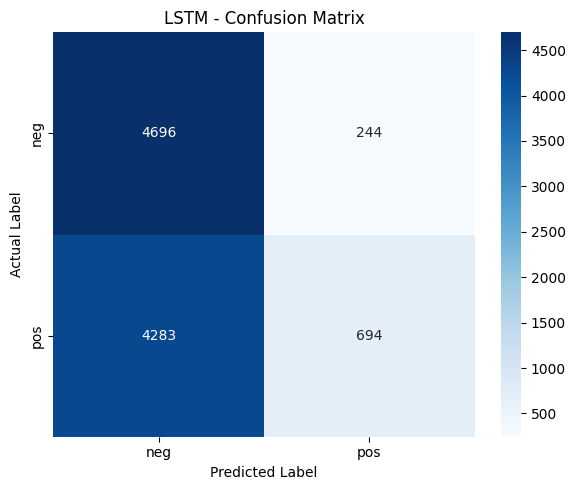

In [57]:
# Evaluate the LSTM on the shared held-out test set
lstm_metrics = evaluate_model("LSTM", y_test, lstm_predictions, lstm_train_time)


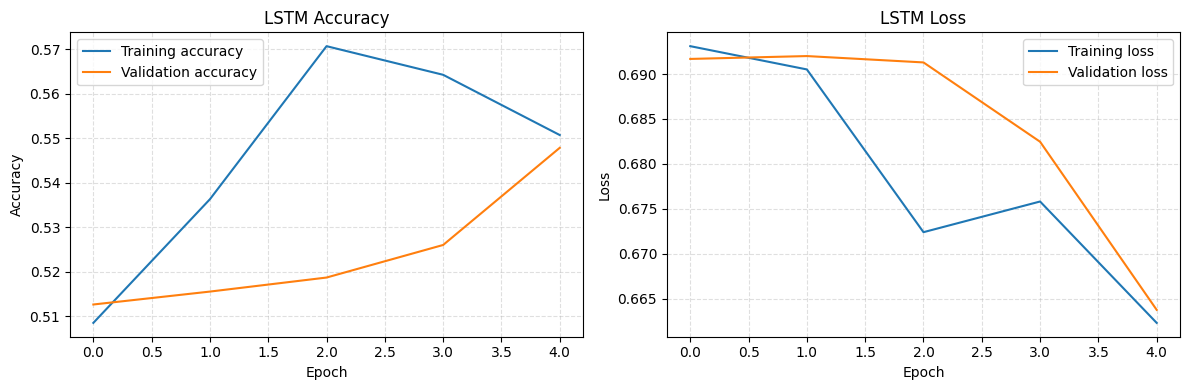

In [58]:
# Plot LSTM training and validation accuracy and loss
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(lstm_history.history["accuracy"], label="Training accuracy")
axes[0].plot(lstm_history.history["val_accuracy"], label="Validation accuracy")
axes[0].set(title="LSTM Accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[0].legend(); axes[0].grid(True, linestyle="--", alpha=0.4)
axes[1].plot(lstm_history.history["loss"], label="Training loss")
axes[1].plot(lstm_history.history["val_loss"], label="Validation loss")
axes[1].set(title="LSTM Loss", xlabel="Epoch", ylabel="Loss")
axes[1].legend(); axes[1].grid(True, linestyle="--", alpha=0.4)
plt.tight_layout(); plt.show()



## 14. GRU Classification

The GRU uses the same padded sequences, training labels, and held-out test split as the Simple RNN and LSTM. Validation comes from the training split only, and EarlyStopping restores the best validation-loss weights.


In [66]:

# Build a GRU model for binary sentiment classification

gru_model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=EMBEDDING_DIM
    ),
    GRU(64),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
], name="gru_sentiment")

gru_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

gru_model.summary()


Model: "gru_sentiment"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [67]:

early_stopping_gru = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

start_time = time.time()

gru_history = gru_model.fit(
    X_train_pad,
    y_train_encoded,
    validation_split=0.2,
    epochs=5,
    batch_size=128,
    callbacks=[early_stopping_gru],
    shuffle=True,
    verbose=1
)

gru_train_time = time.time() - start_time

print(
    f"GRU training completed in {gru_train_time:.2f} seconds."
)


Epoch 1/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 39s 148ms/step - accuracy: 0.5061 - loss: 0.6933 - val_accuracy: 0.5105 - val_loss: 0.6924
Epoch 2/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 37s 149ms/step - accuracy: 0.5240 - loss: 0.6895 - val_accuracy: 0.5176 - val_loss: 0.6897
Epoch 3/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 30s 120ms/step - accuracy: 0.5441 - loss: 0.6709 - val_accuracy: 0.5206 - val_loss: 0.6916
Epoch 4/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 26s 103ms/step - accuracy: 0.5643 - loss: 0.6378 - val_accuracy: 0.5289 - val_loss: 0.7037
GRU training completed in 132.06 seconds.


In [68]:

gru_probabilities = gru_model.predict(
    X_test_pad,
    batch_size=128
).ravel()

gru_predictions_encoded = (
    gru_probabilities >= 0.5
).astype(int)

gru_predictions = label_encoder.inverse_transform(
    gru_predictions_encoded
)

print("GRU predictions generated.")
print(gru_predictions[:10])


78/78 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step
GRU predictions generated.
['neg' 'pos' 'pos' 'pos' 'pos' 'pos' 'pos' 'pos' 'pos' 'pos']


GRU - Evaluation Metrics
--------------------------------------------------
Accuracy: 0.5149
Macro Precision: 0.5571
Macro Recall: 0.5132
Macro F1: 0.3984
Weighted F1: 0.3994
Training Time (seconds): 132.0559

Classification Report:
              precision    recall  f1-score   support

         neg       0.61      0.08      0.13      4940
         pos       0.51      0.95      0.66      4977

    accuracy                           0.51      9917
   macro avg       0.56      0.51      0.40      9917
weighted avg       0.56      0.51      0.40      9917



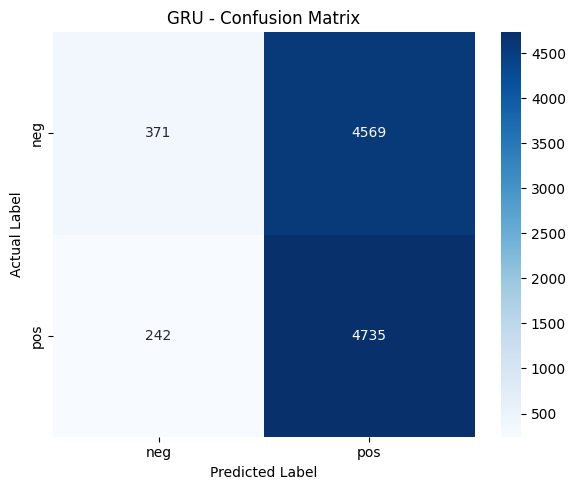

In [69]:

gru_metrics = evaluate_model(
    model_name="GRU",
    y_true=y_test,
    y_pred=gru_predictions,
    train_time=gru_train_time
)


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    gru_history.history["accuracy"],
    label="Training accuracy"
)
axes[0].plot(
    gru_history.history["val_accuracy"],
    label="Validation accuracy"
)
axes[0].set(
    title="GRU Accuracy",
    xlabel="Epoch",
    ylabel="Accuracy"
)
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    gru_history.history["loss"],
    label="Training loss"
)
axes[1].plot(
    gru_history.history["val_loss"],
    label="Validation loss"
)
axes[1].set(
    title="GRU Loss",
    xlabel="Epoch",
    ylabel="Loss"
)
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


## 15. Five-Model Comparison

SVM, Multinomial Naive Bayes, Simple RNN, LSTM and GRU are compared using their evaluation metrics and training durations. All five models use the same held-out test set.

All models use the same train/test split. SVM and Naive Bayes use TF-IDF features; Simple RNN, LSTM and GRU use the shared padded sequences.

This comparison provides an assessment of their classification performance and computational efficiency before comparing them with the deep learning models.

### Performance Comparison Table

The evaluation results of SVM and Naive Bayes are organized into a single table.

The comparison includes Accuracy, Macro Precision, Macro Recall, Macro F1-score, Weighted F1-score, and Training Time.

These metrics provide a consistent basis for examining the strengths and limitations of both traditional classifiers.

In [70]:
# Combine evaluation results for all four models

all_models_results = pd.DataFrame([
    svm_metrics,
    nb_metrics,
    rnn_metrics,
    lstm_metrics,
    gru_metrics
])

display(all_models_results.round(4))



,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (seconds)
0,SVM,0.8912,0.8913,0.8912,0.8912,0.8912,1.2921
1,Naive Bayes,0.8605,0.8606,0.8605,0.8605,0.8605,0.1978
2,Simple RNN,0.5017,0.5053,0.5029,0.4394,0.4387,32.7923
3,LSTM,0.5435,0.6314,0.5450,0.4547,0.4539,130.0421
4,GRU,0.5149,0.5571,0.5132,0.3984,0.3994,132.0559


### Accuracy and Macro F1-score Comparison

Accuracy and Macro F1-score are visualized to compare the classification performance of all five models.

Accuracy measures the proportion of correctly classified reviews, while Macro F1-score gives equal importance to the performance of each sentiment class.

Using both metrics provides a more balanced view of the classifiers' performance.

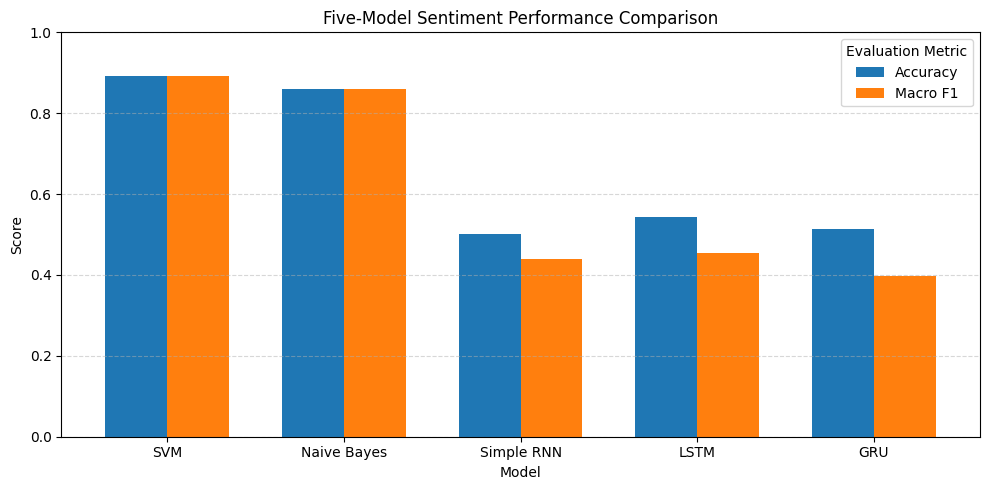

In [77]:
# Visualize Accuracy and Macro F1-score for all five models
comparison_metrics = ["Accuracy", "Macro F1"]
ax = all_models_results.set_index("Model")[comparison_metrics].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), width=0.7
)
plt.title("Five-Model Sentiment Performance Comparison")
plt.xlabel("Model"); plt.ylabel("Score"); plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout(); plt.show()


## 16. Unseen Movie Review Prediction

This section evaluates the trained traditional machine learning classifiers on five newly written movie reviews that are separate from the original IMDb dataset.

The Support Vector Machine (SVM) and Multinomial Naive Bayes models generate sentiment predictions for each review.

The original training preprocessing function and fitted TF-IDF vectorizer are reused to maintain consistency between training and prediction.

The predicted sentiment labels are compared to examine how both classifiers respond to previously unseen review text.

### Prepare Unseen Movie Reviews

Five original movie reviews are created to test the trained classifiers on text that was not used during model training or evaluation.

The examples cover different expressions of positive and negative sentiment, including opinions about acting, storytelling, characters, and overall movie quality.

In [82]:
# Prepare five original unseen movie reviews

unseen_reviews = [
    "The movie was absolutely fantastic, with brilliant acting and an engaging story.",

    "I found the film boring and disappointing, and I would not recommend watching it.",

    "The performances were excellent, but the story was weak and poorly developed.",

    "This was one of the most enjoyable films I have watched in years.",

    "The movie had terrible dialogue, confusing scenes, and a very disappointing ending."
]

# Display the unseen reviews
for index, review in enumerate(unseen_reviews, start=1):
    print(f"Review {index}: {review}")
    print("-" * 80)

Review 1: The movie was absolutely fantastic, with brilliant acting and an engaging story.
--------------------------------------------------------------------------------
Review 2: I found the film boring and disappointing, and I would not recommend watching it.
--------------------------------------------------------------------------------
Review 3: The performances were excellent, but the story was weak and poorly developed.
--------------------------------------------------------------------------------
Review 4: This was one of the most enjoyable films I have watched in years.
--------------------------------------------------------------------------------
Review 5: The movie had terrible dialogue, confusing scenes, and a very disappointing ending.
--------------------------------------------------------------------------------


### Apply the Training Preprocessing Pipeline

The same text preprocessing function used during model development is applied to the unseen reviews.

This ensures that the new text follows the same cleaning, tokenization, stopword removal, and lemmatization steps used during training.

The fitted TF-IDF vectorizer is then reused to transform the processed reviews into numerical feature vectors without fitting it again.

In [83]:
# Apply the existing preprocessing function

unseen_processed = [
    preprocess_text(review)
    for review in unseen_reviews
]

# Transform reviews using the previously fitted TF-IDF vectorizer
unseen_tfidf = tfidf_vectorizer.transform(unseen_processed)

print("Unseen reviews preprocessing completed.")
print("Unseen TF-IDF shape:", unseen_tfidf.shape)

display(
    pd.DataFrame({
        "Original Review": unseen_reviews,
        "Processed Review": unseen_processed
    })
)

Unseen reviews preprocessing completed.
Unseen TF-IDF shape: (5, 10000)


,Original Review,Processed Review
0,"The movie was absolutely fantastic, with brill...",movie absolutely fantastic brilliant acting en...
1,"I found the film boring and disappointing, and...",found film boring disappointing would not reco...
2,"The performances were excellent, but the story...",performance excellent story weak poorly developed
3,This was one of the most enjoyable films I hav...,one enjoyable film watched year
4,"The movie had terrible dialogue, confusing sce...",movie terrible dialogue confusing scene disapp...


### Generate Sentiment Predictions

The trained SVM and Naive Bayes classifiers are applied to the transformed unseen reviews.

Both models use the same TF-IDF feature representation and their previously learned parameters to generate positive or negative sentiment predictions.

No additional model training or feature fitting is performed during this step.

In [84]:
# Generate predictions using both trained classifiers

unseen_svm_predictions = svm_model.predict(unseen_tfidf)

unseen_nb_predictions = nb_model.predict(unseen_tfidf)

print("Unseen text predictions generated successfully.")

Unseen text predictions generated successfully.


In [85]:

# Convert unseen reviews into padded sequences
unseen_sequences = tokenizer.texts_to_sequences(unseen_processed)

unseen_pad = pad_sequences(
    unseen_sequences,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

# Simple RNN predictions
unseen_rnn_probabilities = rnn_model.predict(
    unseen_pad, verbose=0
).ravel()

unseen_rnn_encoded = (
    unseen_rnn_probabilities >= 0.5
).astype(int)

unseen_rnn_predictions = label_encoder.inverse_transform(
    unseen_rnn_encoded
)

# LSTM predictions
unseen_lstm_probabilities = lstm_model.predict(
    unseen_pad, verbose=0
).ravel()

unseen_lstm_encoded = (
    unseen_lstm_probabilities >= 0.5
).astype(int)

unseen_lstm_predictions = label_encoder.inverse_transform(
    unseen_lstm_encoded
)

# GRU predictions
unseen_gru_probabilities = gru_model.predict(
    unseen_pad, verbose=0
).ravel()

unseen_gru_encoded = (
    unseen_gru_probabilities >= 0.5
).astype(int)

unseen_gru_predictions = label_encoder.inverse_transform(
    unseen_gru_encoded
)

print("Predictions generated for all five models.")


Predictions generated for all five models.


### Compare Unseen Text Predictions

The sentiment predictions generated by SVM and Naive Bayes are organized into a comparison table.

The table displays each original review alongside the predicted sentiment from both classifiers, making it possible to identify agreements and differences in their predictions.

In [86]:
# Create a comparison table for unseen review predictions

unseen_predictions_results = pd.DataFrame({
    "Review": unseen_reviews,
    "SVM Prediction": unseen_svm_predictions,
    "Naive Bayes Prediction": unseen_nb_predictions,
    "Simple RNN Prediction": unseen_rnn_predictions,
    "LSTM Prediction": unseen_lstm_predictions,
    "GRU Prediction": unseen_gru_predictions
})

display(unseen_predictions_results)


,Review,SVM Prediction,Naive Bayes Prediction,Simple RNN Prediction,LSTM Prediction,GRU Prediction
0,"The movie was absolutely fantastic, with brill...",pos,pos,neg,neg,pos
1,"I found the film boring and disappointing, and...",neg,neg,neg,neg,pos
2,"The performances were excellent, but the story...",neg,neg,neg,neg,pos
3,This was one of the most enjoyable films I hav...,pos,pos,neg,neg,pos
4,"The movie had terrible dialogue, confusing sce...",neg,neg,neg,neg,pos


In [87]:
# Compare prediction agreement between the two classifiers

agreement_count = (
    unseen_svm_predictions == unseen_nb_predictions
).sum()

total_reviews = len(unseen_reviews)

agreement_percentage = (
    agreement_count / total_reviews
) * 100

print(f"Agreements: {agreement_count}/{total_reviews}")
print(f"Prediction Agreement: {agreement_percentage:.2f}%")

Agreements: 5/5
Prediction Agreement: 100.00%
